# Notebook 04: Quantum Emergence

**Goal:** Show explicitly that a qubit density matrix maps to a stochastic state,
that quantum evolution produces an indivisible process, and that the Born rule
emerges naturally.

By the end of this notebook you will be able to:
- Convert a density matrix to a stochastic state vector
- Verify that qubit evolution is indivisible
- Compute measurement probabilities via the Born rule

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from isp.quantum import (
    density_matrix_to_stochastic_state,
    unitary_to_transition_matrix,
    make_qubit_sigmax_process,
    born_rule,
)
from isp.divisibility import check_divisibility, indivisibility_signature
from isp.visualization import plot_transition_matrix, plot_probability_evolution

## 1. Density Matrix → Stochastic State

A qubit density matrix $\rho$ encodes a probability distribution via its diagonal.
The diagonal entries $\rho_{ii}$ are the Born-rule probabilities for the
computational basis.

In [2]:
# Mixed qubit state: 70% |0⟩, 30% |1⟩, with coherences
rho = np.array([[0.7,  0.1 + 0.2j],
                [0.1 - 0.2j,  0.3]])

print("Density matrix ρ:")
print(rho)
print(f"\nTrace: {np.trace(rho).real:.4f}  (must be 1.0)")
print(f"Eigenvalues (must be ≥ 0): {np.linalg.eigvalsh(rho).round(4)}")

p = density_matrix_to_stochastic_state(rho)
print(f"\nStochastic state vector p = {p}")
print(f"Sum: {p.sum():.4f}")

Density matrix ρ:
[[0.7+0.j  0.1+0.2j]
 [0.1-0.2j 0.3+0.j ]]

Trace: 1.0000  (must be 1.0)
Eigenvalues (must be ≥ 0): [0.2 0.8]

Stochastic state vector p = [0.7 0.3]
Sum: 1.0000


## 2. Quantum Evolution Is Indivisible

The sigma_x qubit process is indivisible. Let's verify this formally
and measure how deep into quantum territory it sits.

In [3]:
times = np.linspace(0, 2 * np.pi, 8).tolist()
proc = make_qubit_sigmax_process(omega=1.0, times=times)

result = check_divisibility(proc)
sig = indivisibility_signature(proc)

print(f"Divisible: {result['divisible']}")
print(f"Failure mode: {result['failure_mode']}")
print(f"Indivisibility signature: {sig:.4f}")

Divisible: False
Failure mode: negative_entries
Indivisibility signature: 1.7470


## 3. The Born Rule Emerges Naturally

Once we have a density matrix and a measurement operator, the Born rule
$P(\text{outcome}) = \text{Tr}(M \rho)$ gives the probability.
This is not an additional postulate in the ISP framework — it follows
from the stochastic structure.

In [4]:
# Projective measurement onto |0⟩ and |1⟩
M0 = np.array([[1, 0], [0, 0]])
M1 = np.array([[0, 0], [0, 1]])

p0 = born_rule(rho, M0)
p1 = born_rule(rho, M1)

print(f"P(measure |0⟩) = {p0:.4f}")
print(f"P(measure |1⟩) = {p1:.4f}")
print(f"Sum (must be 1.0): {p0 + p1:.4f}")
print(f"\nStochastic state gives: {density_matrix_to_stochastic_state(rho)}")
print("(Born rule and stochastic diagonal agree ✓)")

P(measure |0⟩) = 0.7000
P(measure |1⟩) = 0.3000
Sum (must be 1.0): 1.0000

Stochastic state gives: [0.7 0.3]
(Born rule and stochastic diagonal agree ✓)


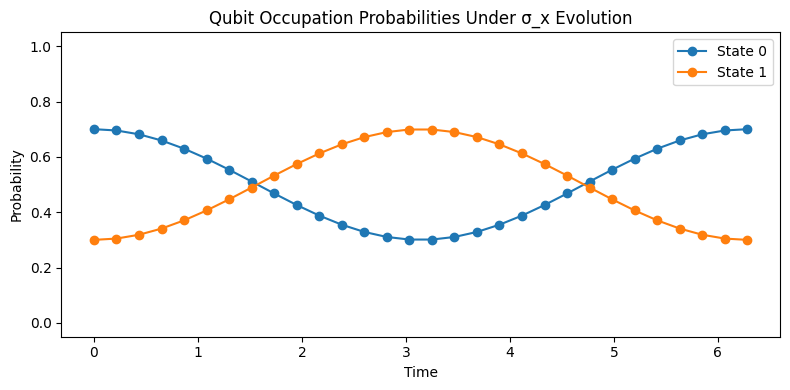

In [5]:
# Evolve the stochastic state and track Born-rule probabilities over time
omega = 1.0
times_dense = np.linspace(0, 2 * np.pi, 30).tolist()
proc_dense = make_qubit_sigmax_process(omega=omega, times=times_dense)

p0_vec = density_matrix_to_stochastic_state(rho)
fig = plot_probability_evolution(proc_dense, p0_vec,
                                 title="Qubit Occupation Probabilities Under σ_x Evolution")
plt.tight_layout()
plt.show()

## Summary

- Density matrices project onto stochastic states via their diagonal
- Qubit evolution under any non-trivial Hamiltonian produces an indivisible process
- The Born rule is a natural consequence, not an extra postulate
- This is the core of Barandes' claim: quantum mechanics *is* an indivisible stochastic process

**Next:** Notebook 05 builds the payoff — a double-slit model where
interference emerges from indivisibility.